# Graph neural networks for weather data with anemoi-graphs

**ECMWF training course: Machine learning for weather forecasting, 16–20 November 2026, Day 2**

In this notebook, you make a graph neural network (GNN). You use it to **downscale the ERA5 2 m temperature** on the globe, from a coarse grid (approximately 7.5°) to a finer grid (approximately 2°). You read the data with [`anemoi-datasets`](https://anemoi.readthedocs.io/projects/datasets/en/latest/) and you make the graphs with [`anemoi-graphs`](https://anemoi.readthedocs.io/projects/graphs/en/latest/). AIFS uses the same packages.

**Learning objectives.** When you complete this notebook, you can:

1. Explain what a graph is and how a computer keeps a graph in memory.
2. Make graphs on the sphere with `anemoi-graphs`, and inspect them.
3. Explain the three steps of message passing: *message*, *aggregation* and *update*.
4. Write a GNN layer with PyTorch Geometric.
5. Train a GNN and compare it with two baselines that do not use machine learning.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup and data | 3 min |
| 1 | Graphs and how a computer keeps them | 9 min |
| 2 | Reduced Gaussian grids and the downscaling task | 7 min |
| 3 | Graphs on the sphere with anemoi-graphs | 10 min |
| 4 | Message passing | 12 min |
| 5 | Train and evaluate the GNN | 7 min |
| 6 | Summary | 2 min |
| 7 | ⭐ Optional: a graph transformer layer (after the session) | 30 min |

**How to use this notebook**

- Run the cells in sequence, from the top to the bottom.
- ✏️ shows an exercise. Write your code in the cell below the text of the exercise.
- 💡 shows a hint. Click it to open it. Try the exercise before you open the hints.
- ⭐ shows the optional exercise. Do it after the session, or if you have time.
- ✅ shows a solution.

> **NOTE:** The notebook runs on a CPU or on a GPU. On a GPU, each training takes less than one minute and the full notebook runs in approximately 2 minutes. On a CPU with 8 cores, each training takes approximately 5 minutes.

## 0. Setup and data

Run the cell below to import the packages. The file `gnn_helpers.py` contains the code that is not specific to graphs: the code that loads the data, the training loop and the plots. You can read it if you want to know the details, but it is not necessary.

In [1]:
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch_geometric.nn import MessagePassing
from torch_geometric.utils import softmax

import anemoi.datasets
import anemoi.graphs
from anemoi.datasets import open_dataset
from anemoi.graphs.create import GraphCreator
from anemoi.graphs.utils import get_grid_reference_distance

import gnn_helpers as H
from gnn_helpers import DownscalingDataset, GraphDownscaler, rmse

# anemoi-graphs writes a warning if the optional package torch-cluster is not installed. You can ignore it.
logging.getLogger("anemoi").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})

H.set_seed(42)
DEVICE = H.get_device()
print(f"torch {torch.__version__}, anemoi-datasets {anemoi.datasets.__version__}, "
      f"anemoi-graphs {anemoi.graphs.__version__}, device: {DEVICE}")

/home/syma/venvs/aifs-dop-ac/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.9.0+cu128, anemoi-datasets 0.5.45, anemoi-graphs 0.9.6.post35, device: cpu


### 0.1 Read the data with anemoi-datasets

We use the anemoi dataset [`aifs-ea-an-oper-0001-mars-o48-2010-2022-6h-v1-toy`](https://anemoi.ecmwf.int/datasets/aifs-ea-an-oper-0001-mars-o48-2010-2022-6h-v1-toy). It is a small version of the datasets that train AIFS: ERA5 on the octahedral reduced Gaussian grid **O48** (approximately 2°, 10 944 grid points), every 6 hours from 2010 to 2022. Section 2.1 explains reduced Gaussian grids.

The function `open_dataset` of anemoi-datasets opens the dataset. It reads only the data that you ask for:

- `start` and `end`: the first and the last date. Here, we give years.
- `frequency`: the time between two dates. We use 12 h (00 UTC and 12 UTC).
- `select`: the variables. We use the 2 m temperature (`2t`), the surface geopotential (`z`) and the land-sea mask (`lsm`).

The data has the shape (dates, variables, ensemble members, grid points). The grid is not a rectangle. Thus, there are no separate dimensions for the latitude and the longitude: each grid point is one position in the last dimension. `ds.latitudes` and `ds.longitudes` give the coordinates of the grid points.

> **NOTE:** The dataset is on the file system of the virtual machine or ECMWF HPC. On a different computer, set the environment variable `GNN_DATASET` to the path of your copy before you start the notebook. Also change the path in the YAML files of Part 3.

In [2]:
ds = open_dataset(H.DATASET, start=2020, end=2021, frequency="12h", select=["2t", "z", "lsm"])
print("shape:", ds.shape, " variables:", ds.variables, " grid:", ds.resolution)
print("dates:", ds.dates[0], "...", ds.dates[-1])
print("first 3 grid points (lat, lon):", [(float(la), float(lo)) for la, lo in zip(ds.latitudes[:3], ds.longitudes[:3])])

shape: (1462, 3, 1, 10944)  variables: ['2t', 'z', 'lsm']  grid: O48
dates: 2020-01-01T00:00:00 ... 2021-12-31T12:00:00
first 3 grid points (lat, lon): [(88.57216851400727, 0.0), (88.57216851400727, 18.0), (88.57216851400727, 36.0)]


The function `H.load_era5` uses `open_dataset` in the same way. It reads the values into memory as NumPy arrays: 2020 for the training and 2021 for the validation. It also changes the surface geopotential to a height in metres (the orography).

In [3]:
train_sample = H.load_era5(start=2020, end=2020)
val_sample = H.load_era5(start=2021, end=2021)
print(f"Training: {train_sample.t2m.shape[0]} times, validation: {val_sample.t2m.shape[0]} times, "
      f"{train_sample.num_points} grid points")

Training: 732 times, validation: 730 times, 10944 grid points


## 1. Graphs and how a computer keeps them

### 1.1 What is a graph?

A **graph** $G = (V, E)$ has two parts:

- A set of **nodes** $V$ (also known as *vertices*). A node is an object, for example a weather station or a grid point.
- A set of **edges** $E$. An edge connects two nodes. It shows that the two nodes have a relation, for example "these two stations are near each other".

An edge can have a direction. The edge $j \rightarrow i$ goes from the **source node** $j$ to the **target node** $i$. In a GNN, information moves along the edges, from the source node to the target node. To show a connection in the two directions, you use two edges: $j \rightarrow i$ and $i \rightarrow j$.

Nodes and edges can have **features** (also known as *attributes*). These are numbers that describe them:

- A **node feature** describes one node. Examples: the temperature, the height of the orography, the land-sea mask.
- An **edge feature** describes the relation between two nodes. Examples: the distance between the nodes, the direction from the source node to the target node.

Graphs are not new in meteorology. A network of weather stations is a graph. The grid of a numerical model is also a graph: each grid point has a connection to its neighbours. AIFS, the data-driven model of ECMWF, uses graphs to move information between the model grid and a coarser "hidden" grid.

### 1.2 A small example: weather centres in Europe

We make a small graph with 8 nodes. Each node is a city with a weather centre. The node feature is the ERA5 2 m temperature at the nearest O48 grid point, at 00 UTC on 12 January 2021.

In [4]:
cities = {
    # name: (latitude, longitude)
    "Reading (ECMWF)": (51.44, -0.94),
    "Exeter (Met Office)": (50.73, -3.47),
    "De Bilt (KNMI)": (52.10, 5.18),
    "Bonn (ECMWF)": (50.73, 7.10),
    "Offenbach (DWD)": (50.10, 8.76),
    "Toulouse (Météo-France)": (43.60, 1.44),
    "Bologna (ECMWF)": (44.49, 11.34),
    "Vienna (GeoSphere)": (48.25, 16.36),
}
names = list(cities)
city_lat = np.array([cities[n][0] for n in names])
city_lon = np.array([cities[n][1] for n in names])

# Node feature: the ERA5 2 m temperature at the nearest grid point
time_index = int(np.where(val_sample.times == np.datetime64("2021-01-12T00"))[0][0])
nearest = [H.nearest_node(val_sample.latitudes, val_sample.longitudes, la, lo) for la, lo in zip(city_lat, city_lon)]
x = torch.tensor(val_sample.t2m[time_index, nearest] - 273.15, dtype=torch.float32).unsqueeze(-1)  # shape (8, 1)

# The connections between the cities. Each pair is connected in the two directions.
pairs = [(0, 1), (0, 2), (0, 5), (1, 5), (2, 3), (3, 4), (4, 6), (4, 7), (5, 6), (6, 7)]
edge_list = pairs + [(j, i) for (i, j) in pairs]

for i, n in enumerate(names):
    print(f"node {i}: {n:25s} T = {x[i, 0]:6.1f} °C")
print(f"\n{len(edge_list)} directed edges: {edge_list}")

node 0: Reading (ECMWF)           T =    7.7 °C
node 1: Exeter (Met Office)       T =    9.2 °C
node 2: De Bilt (KNMI)            T =    7.1 °C
node 3: Bonn (ECMWF)              T =    3.6 °C
node 4: Offenbach (DWD)           T =   -2.7 °C
node 5: Toulouse (Météo-France)   T =   -1.5 °C
node 6: Bologna (ECMWF)           T =    0.5 °C
node 7: Vienna (GeoSphere)        T =   -5.9 °C

20 directed edges: [(0, 1), (0, 2), (0, 5), (1, 5), (2, 3), (3, 4), (4, 6), (4, 7), (5, 6), (6, 7), (1, 0), (2, 0), (5, 0), (5, 1), (3, 2), (4, 3), (6, 4), (7, 4), (6, 5), (7, 6)]


### 1.3 Three ways to keep a graph in memory

A computer can keep the same graph in three ways:

1. **Edge list.** A list of pairs `(source, target)`. This is the list `edge_list` above.
2. **Adjacency matrix** $A$. This is an $N \times N$ matrix for $N$ nodes. In this notebook, $A_{ij} = 1$ if there is an edge from node $j$ to node $i$. If not, $A_{ij} = 0$. Thus, row $i$ shows the nodes that send information to node $i$.
3. **`edge_index`** (also known as the *COO format*). This is a tensor with shape `(2, num_edges)`. Row 0 contains the source nodes. Row 1 contains the target nodes. **PyTorch Geometric and anemoi-graphs use this format.**

Most graphs in weather models are **sparse**: each node connects to a small number of other nodes. For a sparse graph, `edge_index` uses much less memory than the adjacency matrix. In Part 3, our downscaling graph has 1 008 source nodes, 10 944 target nodes and 43 776 edges. The adjacency matrix has 11 031 552 values, but `edge_index` has only 87 552.

In [5]:
edge_index = torch.tensor(edge_list, dtype=torch.long).T  # shape (2, num_edges)
print("edge_index =\n", edge_index)
print("shape:", tuple(edge_index.shape))

edge_index =
 tensor([[0, 0, 0, 1, 2, 3, 4, 4, 5, 6, 1, 2, 5, 5, 3, 4, 6, 7, 6, 7],
        [1, 2, 5, 5, 3, 4, 6, 7, 6, 7, 0, 0, 0, 1, 2, 3, 4, 4, 5, 6]])
shape: (2, 20)


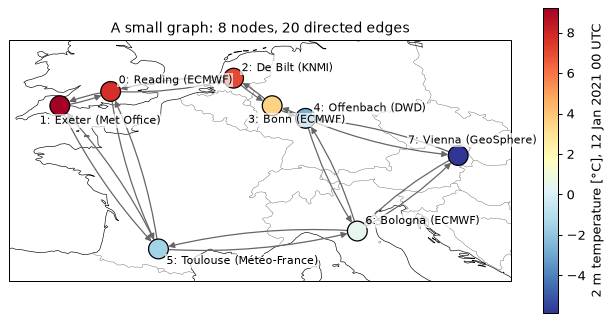

In [6]:
fig = plt.figure(figsize=(9, 5.5))
ax = H.map_axes(fig, 1, 1, 1, extent=(-6, 19, 42, 54))
for j, i in edge_list:  # draw an arrow from the source j to the target i
    ax.annotate("", xy=(city_lon[i], city_lat[i]), xytext=(city_lon[j], city_lat[j]),
                arrowprops=dict(arrowstyle="-|>", color="0.4", lw=1, shrinkA=8, shrinkB=8,
                                connectionstyle="arc3,rad=0.08"))
sc = H.plot_points(ax, city_lat, city_lon, x[:, 0].numpy(), s=250, cmap=H.TEMP_CMAP, edgecolors="k", zorder=3)
label_offsets = {0: (0.4, 0.4), 1: (-1.0, -0.9), 2: (0.4, 0.35), 3: (-1.2, -0.85), 4: (0.4, 0.35),
                 5: (0.4, -0.75), 6: (0.4, 0.35), 7: (-2.5, 0.6)}
for i, n in enumerate(names):
    dx, dy = label_offsets[i]
    ax.text(city_lon[i] + dx, city_lat[i] + dy, f"{i}: {n}", fontsize=9, zorder=4,
            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1))
fig.colorbar(sc, ax=ax, shrink=0.8, label="2 m temperature [°C], 12 Jan 2021 00 UTC")
ax.set_title("A small graph: 8 nodes, 20 directed edges")
plt.show()

### ✏️ Exercise 1: from `edge_index` to the adjacency matrix

Use the tensors `edge_index` (shape `(2, 20)`) and `x` (shape `(8, 1)`) from above.

1. Make the adjacency matrix `A` (shape `(8, 8)`). Use the convention of Section 1.3: `A[i, j] = 1` if there is an edge from node `j` to node `i`.
2. Count the incoming edges of each node. This number is the **in-degree** of the node. Do this calculation in two ways: from `A` and from `edge_index`.
3. Calculate, for each node, the **mean temperature of the nodes that send it an edge**. Use only one matrix product and one division.

<details><summary><b>💡 Hint 1</b> (click to open)</summary>

You can use tensor indices to set many values at the same time: `A[rows, cols] = 1`. Which row of `edge_index` gives the target nodes (the rows of `A`)?

</details>

<details><summary><b>💡 Hint 2</b> (click to open)</summary>

- From `A`: add the values in each row with `A.sum(dim=1)`.
- From `edge_index`: count how many times each node index occurs in `edge_index[1]`. The function `torch.bincount` does this.

</details>

<details><summary><b>💡 Hint 3</b> (click to open)</summary>

The product `A @ x` gives, for each node $i$, the sum $\sum_j A_{ij} x_j$. This is the sum of the temperatures of the source nodes of $i$. Divide it by the in-degree.

</details>

Reading (ECMWF)           in-degree = 3  T =    7.7 °C  mean T of the neighbours =    4.9 °C
Exeter (Met Office)       in-degree = 2  T =    9.2 °C  mean T of the neighbours =    3.1 °C
De Bilt (KNMI)            in-degree = 2  T =    7.1 °C  mean T of the neighbours =    5.6 °C
Bonn (ECMWF)              in-degree = 2  T =    3.6 °C  mean T of the neighbours =    2.2 °C
Offenbach (DWD)           in-degree = 3  T =   -2.7 °C  mean T of the neighbours =   -0.6 °C
Toulouse (Météo-France)   in-degree = 3  T =   -1.5 °C  mean T of the neighbours =    5.8 °C
Bologna (ECMWF)           in-degree = 3  T =    0.5 °C  mean T of the neighbours =   -3.4 °C
Vienna (GeoSphere)        in-degree = 2  T =   -5.9 °C  mean T of the neighbours =   -1.1 °C


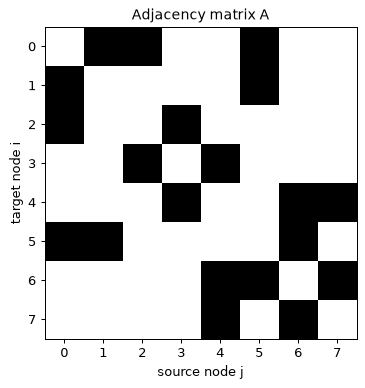

In [7]:
num_nodes = x.shape[0]

# 1. Adjacency matrix: A[target, source] = 1
A = torch.zeros(num_nodes, num_nodes)
A[edge_index[1], edge_index[0]] = 1.0

# 2. In-degree, two ways
in_degree_from_A = A.sum(dim=1)
in_degree_from_edge_index = torch.bincount(edge_index[1], minlength=num_nodes)
assert torch.equal(in_degree_from_A.long(), in_degree_from_edge_index)

# 3. Mean temperature of the neighbours
neighbour_mean = (A @ x) / in_degree_from_A.unsqueeze(-1)

for i, n in enumerate(names):
    print(f"{n:25s} in-degree = {int(in_degree_from_A[i])}  T = {x[i, 0]:6.1f} °C  "
          f"mean T of the neighbours = {neighbour_mean[i, 0]:6.1f} °C")

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(A, cmap="Greys")
ax.set(xticks=range(num_nodes), yticks=range(num_nodes), xlabel="source node j", ylabel="target node i",
       title="Adjacency matrix A")
plt.show()

#### ✅ Solution

- `edge_index[1]` gives the targets (the rows of `A`) and `edge_index[0]` gives the sources (the columns of `A`).
- The in-degree is the sum of each row of `A`. It is also the number of times that each node occurs as a target in `edge_index[1]`.
- `A @ x` adds the temperatures of the neighbours. When you divide by the in-degree, you get the mean.

The graph is undirected (all edges go in the two directions), thus `A` is symmetric.

**This is already a graph neural network operation!** In part 3 of the exercise, each node collects information from its neighbours and combines it. A GNN does the same thing, with two differences:

1. The GNN **learns** how to make the messages and how to combine them. Here, the operation is a fixed mean.
2. The GNN does not use the matrix `A`. It uses `edge_index` to collect the messages, because `A` is too large for real graphs (see Part 4).

### 1.4 Bipartite graphs

In the example above, all nodes are of the same type. In weather models, we often have **two sets of nodes**, for example the nodes of a coarse grid and the nodes of a fine grid. A graph where all edges go from one set of nodes to a different set of nodes is a **bipartite graph**.

AIFS uses an **encoder–processor–decoder** structure:

- The **encoder** sends information from the data grid (for example, the ERA5 grid points) to a coarser hidden mesh. This is a bipartite graph.
- The **processor** does many steps of message passing on the hidden mesh. The source and target nodes are the same set of nodes.
- The **decoder** sends the information back from the hidden mesh to the data grid. This is a bipartite graph.

In this notebook, we make a decoder-type graph: **coarse grid → fine grid**. PyTorch Geometric keeps graphs with more than one type of nodes in a `HeteroData` object. anemoi-graphs makes `HeteroData` objects. You will see one in Part 3.

## 2. Reduced Gaussian grids and the downscaling task

### 2.1 Reduced Gaussian grids

The data of this notebook is on a **reduced Gaussian grid**. ECMWF uses this type of grid for the IFS, for ERA5 and for AIFS.

**The problem of a regular grid.** A regular latitude–longitude grid has the same number of points on each circle of latitude. But the circles of latitude near the poles are short. Thus, near the poles, the points are very near to each other, and the grid has too many points there.

**Gaussian grids.** A Gaussian grid uses a special set of latitudes: the *Gaussian latitudes*. They are the zeros of a Legendre polynomial. The distance between two Gaussian latitudes is almost constant, and the latitudes are symmetric about the equator. There is no point at the poles. The IFS is a spectral model: it calculates a part of its dynamics with spherical harmonics. With the Gaussian latitudes, the transforms between the grid and the spherical harmonics are exact (*Gaussian quadrature*).

**Reduced Gaussian grids.** A *reduced* Gaussian grid has fewer points on the circles of latitude near the poles. Thus, the distance between a point and its neighbours is approximately the same on all the globe.

**The name of a grid** has a letter and a number, for example `O48` or `N320`:

- The letter gives the type of grid. `N` is the original reduced Gaussian grid of ECMWF. `O` is the *octahedral* reduced Gaussian grid.
- The number $N$ is the number of circles of latitude between a pole and the equator. Thus, the grid has $2N$ circles of latitude.

On an **octahedral** grid, the circle of latitude number $i$ has $4i + 16$ points. Here, $i = 1$ is the circle nearest to a pole, and $i = N$ is the circle nearest to the equator. From one circle to the next, the number of points increases by 4: one more point in each quarter of the globe. The name comes from this structure: an octahedron has 8 triangular faces, and each quarter of a hemisphere is one face. In total, the grid has $4N(N + 9)$ points.

| Grid | Circles of latitude | Points | Distance between circles | Use |
|---|---|---|---|---|
| O12 | 24 | 1 008 | 7.5° (approximately 830 km) | the coarse grid of this notebook |
| O48 | 96 | 10 944 | 1.9° (approximately 210 km) | the toy dataset of this notebook |
| N320 | 640 | 542 080 | 0.28° (approximately 31 km) | ERA5, AIFS |
| O1280 | 2 560 | 6 599 680 | 0.07° (approximately 8 km) | the high-resolution forecast of the IFS |

The function `H.octahedral_grid(N)` calculates the latitudes and the longitudes of the grid O$N$ with these rules. The figure below shows the O12 grid and the O48 grid near the North Pole.

O12: 1008 points. O48: 10944 points. Same O48 points as the dataset: True


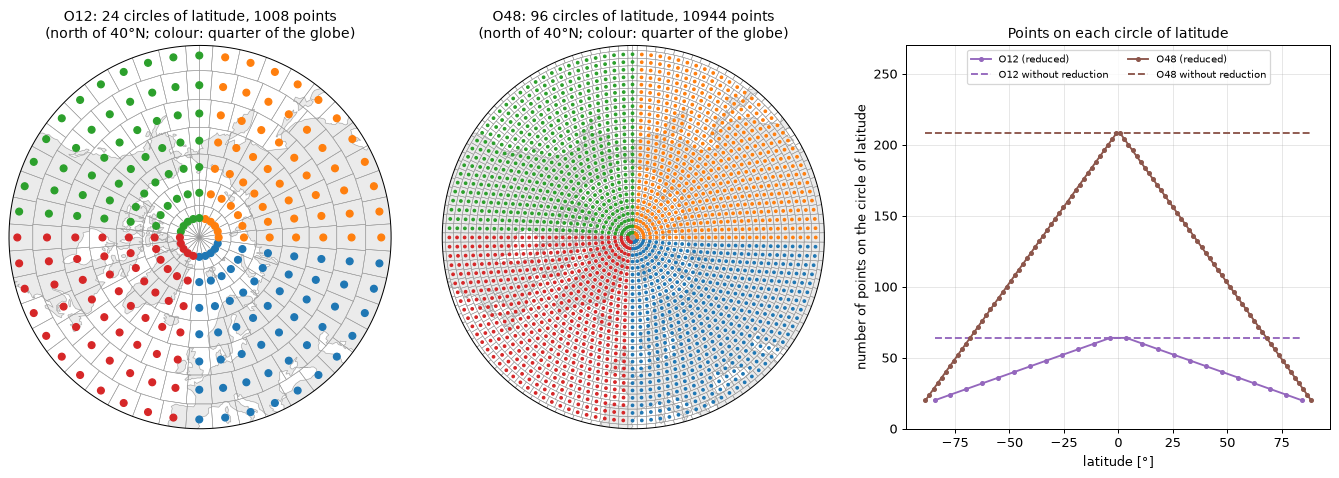

In [8]:
o12_lat, o12_lon = H.octahedral_grid(12)
o48_lat, o48_lon = H.octahedral_grid(48)

# Check: the formula gives exactly the grid points of the dataset
same = np.allclose(o48_lat, val_sample.latitudes) and np.allclose(o48_lon % 360, val_sample.longitudes % 360)
print(f"O12: {o12_lat.size} points. O48: {o48_lat.size} points. Same O48 points as the dataset: {same}")

H.plot_reduced_gaussian_grids({"O12": (o12_lat, o12_lon), "O48": (o48_lat, o48_lon)})
plt.show()

**What do we see?**

- The grey lines are the borders of the grid cells. The maps of this notebook show these cells.
- Near the pole, a circle of latitude has only 20 points. Near the equator, it has 64 points (O12) or 208 points (O48).
- Each colour is one quarter of the globe. In each quarter, the circle number $i$ has $i + 4$ points.
- Without the reduction, all the circles have the same number of points as the equator (the dashed lines in the right plot). The reduced O48 grid has approximately 45 % fewer points than the grid without the reduction.

**Reduced Gaussian grids in anemoi-graphs.** The node builder `ReducedGaussianGridNodes` makes the nodes of a reduced Gaussian grid (see the [documentation](https://anemoi.readthedocs.io/projects/graphs/en/latest/graphs/node_coordinates/reduced_gaussian.html)). In a YAML file:

```yaml
nodes:
  data:
    node_builder:
      _target_: anemoi.graphs.nodes.ReducedGaussianGridNodes
      grid: o48
```

It downloads the coordinates of the grid one time and keeps them in a local cache. Only some grids are available: o16, o32, o48, o96, o160, o256, o320, n320 and o1280. O12 is not in this list. Thus, in Part 3, we give the O12 coordinates to anemoi-graphs in a file.

The cell below makes the O48 nodes with `ReducedGaussianGridNodes` and compares them with our grid. It needs internet access. If it does not work, you can continue: the rest of the notebook does not need it.

In [9]:
from torch_geometric.data import HeteroData
from anemoi.graphs.nodes import ReducedGaussianGridNodes

try:
    rgg = ReducedGaussianGridNodes(grid="o48", name="data").update_graph(HeteroData())
    rgg_lat, rgg_lon = np.rad2deg(rgg["data"].x.cpu().numpy()).T
    print(f"ReducedGaussianGridNodes(grid='o48'): {rgg_lat.size} nodes")
    print("Same points as H.octahedral_grid(48):", np.allclose(rgg_lat, o48_lat) and np.allclose(rgg_lon % 360, o48_lon % 360))
except Exception as err:  # for example, no internet access
    print(f"ReducedGaussianGridNodes did not work ({type(err).__name__}: {err}). You can continue.")

ReducedGaussianGridNodes(grid='o48'): 10944 nodes
Same points as H.octahedral_grid(48): True


### 2.2 The downscaling task

We make a coarse version of the data. The coarse grid is the octahedral grid **O12** (approximately 7.5°, 1 008 points). Each coarse value is the mean of the O48 values in the area of the coarse point. This area contains all the O48 points that are nearer to this coarse point than to the other coarse points.

The model must calculate the fine O48 field from:

- the coarse temperature, orography and land-sea mask,
- the fine orography and land-sea mask, and some time and position information.

This is a **downscaling** task. It is a good task for a first GNN because:

- The input and the output are on two different grids. A bipartite graph connects them in a natural way.
- The physics is clear. In the troposphere, the temperature usually decreases with height, by approximately 6.5 K per km (the *standard lapse rate*). A coarse point on a coast is a mix of land and sea. The fine orography and the fine land-sea mask contain information that the coarse field does not have.
- The physics is also not simple. The lapse rate and the difference between land and sea change with the weather, the time of day and the season. A fixed correction cannot show this.

In [10]:
COARSE_GRID = 12  # O12
train_ds = DownscalingDataset(train_sample, coarse_n=COARSE_GRID)
val_ds = DownscalingDataset(val_sample, coarse_n=COARSE_GRID, t2m_mean=train_ds.t2m_mean, t2m_std=train_ds.t2m_std)

print(f"Training samples: {len(train_ds)}, validation samples: {len(val_ds)}")
print(f"Coarse grid: O{COARSE_GRID}, {train_ds.num_coarse_nodes} points")
print(f"Fine grid:   O48, {train_ds.num_fine_nodes} points")
print(f"Normalisation of the temperature: mean = {train_ds.t2m_mean:.2f} K, std = {train_ds.t2m_std:.2f} K")

Training samples: 732, validation samples: 730
Coarse grid: O12, 1008 points
Fine grid:   O48, 10944 points
Normalisation of the temperature: mean = 287.89 K, std = 15.99 K


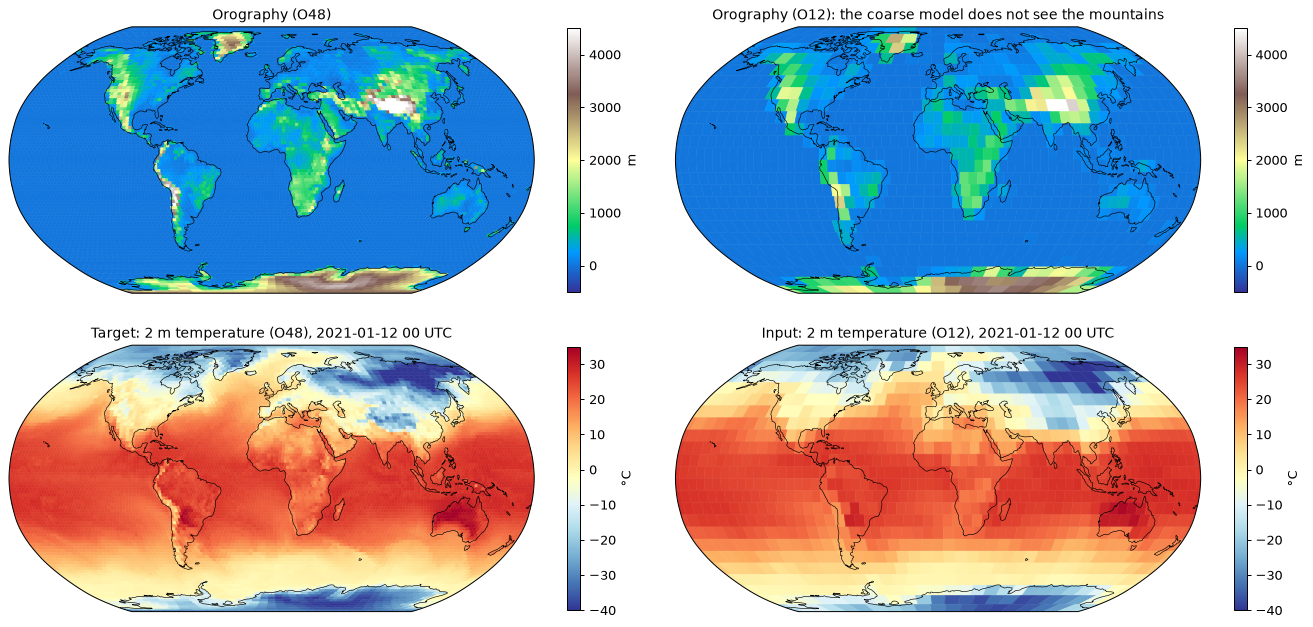

In [11]:
EXAMPLE = val_ds.time_index("2021-01-12T00")

fig = plt.figure(figsize=(15, 7.5))
panels = [
    (val_ds.fine_lat, val_ds.fine_lon, val_ds.orog_fine * 1000, "Orography (O48)", dict(cmap=H.OROG_CMAP, vmin=-500, vmax=4500), "m"),
    (val_ds.coarse_lat, val_ds.coarse_lon, val_ds.orog_coarse * 1000, "Orography (O12): the coarse model does not see the mountains",
     dict(cmap=H.OROG_CMAP, vmin=-500, vmax=4500), "m"),
    (val_ds.fine_lat, val_ds.fine_lon, val_ds.t2m_fine[EXAMPLE] - 273.15, "Target: 2 m temperature (O48), 2021-01-12 00 UTC",
     dict(vmin=-40, vmax=35), "°C"),
    (val_ds.coarse_lat, val_ds.coarse_lon, val_ds.t2m_coarse[EXAMPLE] - 273.15, "Input: 2 m temperature (O12), 2021-01-12 00 UTC",
     dict(vmin=-40, vmax=35), "°C"),
]
for k, (lat, lon, values, title, kwargs, unit) in enumerate(panels):
    ax = H.map_axes(fig, 2, 2, k + 1)
    im = H.plot_field(ax, lat, lon, values, **kwargs)
    fig.colorbar(im, ax=ax, shrink=0.8, label=unit)
    ax.set_title(title)
fig.tight_layout()
plt.show()

The class `DownscalingDataset` (in `gnn_helpers.py`) gives one sample as three tensors:

| Tensor | Shape | Features |
|---|---|---|
| `x_src` (coarse nodes) | `(1008, 3)` | normalised temperature, orography [km], land-sea mask |
| `x_dst` (fine nodes) | `(10944, 10)` | orography [km], land-sea mask, sin/cos of latitude and longitude, sin/cos of the local solar time, sin/cos of the day of the year |
| `y` (fine nodes) | `(10944, 1)` | normalised temperature (the target) |

We normalise the temperature with the mean and the standard deviation of the training data. AIFS also uses "forcings" such as the local solar time and the day of the year as input features. The toy dataset contains these forcings too, but here we calculate them ourselves.

In [12]:
x_src, x_dst, y = train_ds[0]
print("x_src:", tuple(x_src.shape), " x_dst:", tuple(x_dst.shape), " y:", tuple(y.shape))

x_src: (1008, 3)  x_dst: (10944, 10)  y: (10944, 1)


## 3. Graphs on the sphere with anemoi-graphs

[`anemoi-graphs`](https://anemoi.readthedocs.io/projects/graphs/en/latest/) is the package of the Anemoi framework that makes the graphs for data-driven weather models. It makes a PyTorch Geometric `HeteroData` object in two steps:

1. **Node builders** add a set of nodes to the graph. Examples: `AnemoiDatasetNodes` (the grid points of an anemoi dataset), `NPZFileNodes`, `LatLonNodes`, `ReducedGaussianGridNodes`, `TriNodes` (a refined icosahedron, as in AIFS).
2. **Edge builders** add edges between two sets of nodes. Examples: `KNNEdges` (the *k* nearest neighbours), `CutOffEdges` (all nodes nearer than a radius), `MultiScaleEdges` (edges on a refined icosahedron).

In anemoi-training, you do not write Python code for the graph. You write a **YAML configuration**. Then the class `GraphCreator` (or the command line tool `anemoi-graphs create`) makes the graph from it.

### 3.1 The graph configuration

**The nodes.**

- `fine`: `AnemoiDatasetNodes` reads the coordinates of the grid points from the anemoi dataset.
- `coarse`: `NPZFileNodes` reads the coordinates of the O12 grid from a `.npz` file. We write this file first. (`ReducedGaussianGridNodes` does not have the O12 grid, see Section 2.1.)

**The edges** go from `coarse` (source) to `fine` (target). We compare **two options** for the edge builder:

- **Option 1: `KNNEdges`.** Each fine node gets edges from its $k = 4$ nearest coarse nodes.
- **Option 2: `CutOffEdges`.** Each fine node gets edges from **all** the coarse nodes nearer than a radius. You give the radius as a ratio, `cutoff_factor`. The radius is `cutoff_factor` × the *reference distance* of the target nodes. The reference distance is a typical distance between a fine node and its nearest fine neighbour.

**The edge attributes** are the same for the two options:

- `EdgeLength`: the great-circle distance between the two nodes. With `norm: unit-max`, the longest edge has the length 1.
- `EdgeDirection`: a 2D vector that gives the direction of the edge, on the plane that touches the sphere at the target node.

The edge features tell the GNN *where* the source node is, relative to the target node. Without them, the GNN cannot know which coarse node is near and which is far.

In [13]:
Path("graphs").mkdir(exist_ok=True)
np.savez("graphs/grid_o12.npz", latitudes=train_ds.coarse_lat, longitudes=train_ds.coarse_lon)

In [14]:
%%writefile graphs/downscaling_knn.yaml
nodes:
  coarse:
    node_builder:
      _target_: anemoi.graphs.nodes.NPZFileNodes
      npz_file: graphs/grid_o12.npz
  fine:
    node_builder:
      _target_: anemoi.graphs.nodes.AnemoiDatasetNodes
      dataset: /home/mlx/ai-ml/datasets/aifs-ea-an-oper-0001-mars-o48-2010-2022-6h-v1-toy.zarr

edges:
  - source_name: coarse
    target_name: fine
    edge_builders:
      # Option 1: the 4 nearest coarse nodes
      - _target_: anemoi.graphs.edges.KNNEdges
        num_nearest_neighbours: 4
    attributes:
      edge_length:
        _target_: anemoi.graphs.edges.attributes.EdgeLength
        norm: unit-max
      edge_dirs:
        _target_: anemoi.graphs.edges.attributes.EdgeDirection

Overwriting graphs/downscaling_knn.yaml


In [15]:
%%writefile graphs/downscaling_cutoff.yaml
nodes:
  coarse:
    node_builder:
      _target_: anemoi.graphs.nodes.NPZFileNodes
      npz_file: graphs/grid_o12.npz
  fine:
    node_builder:
      _target_: anemoi.graphs.nodes.AnemoiDatasetNodes
      dataset: /home/mlx/ai-ml/datasets/aifs-ea-an-oper-0001-mars-o48-2010-2022-6h-v1-toy.zarr

edges:
  - source_name: coarse
    target_name: fine
    edge_builders:
      # Option 2: all the coarse nodes within a radius of cutoff_factor x (reference distance of the fine nodes)
      - _target_: anemoi.graphs.edges.CutOffEdges
        cutoff_factor: 3.0
    attributes:
      edge_length:
        _target_: anemoi.graphs.edges.attributes.EdgeLength
        norm: unit-max
      edge_dirs:
        _target_: anemoi.graphs.edges.attributes.EdgeDirection

Overwriting graphs/downscaling_cutoff.yaml


`GraphCreator` makes the two graphs and saves them as `.pt` files.

In [16]:
graphs = {}
for option in ("knn", "cutoff"):
    graph = GraphCreator(config=f"graphs/downscaling_{option}.yaml").create(
        save_path=f"graphs/downscaling_{option}.pt", overwrite=True
    )
    # anemoi-graphs puts the graph on the GPU if there is one. We keep it on the CPU for now.
    graphs[option] = graph.cpu()
print(graphs["knn"])

reference_km = get_grid_reference_distance(graphs["knn"]["fine"].x) * 6371.0
print(f"\nReference distance of the fine nodes: {reference_km:.0f} km -> cut-off radius = 3.0 x {reference_km:.0f} km = {3.0 * reference_km:.0f} km")

HeteroData(
  coarse={
    x=[1008, 2],
    node_type='NPZFileNodes',
  },
  fine={
    x=[10944, 2],
    node_type='AnemoiDatasetNodes',
  },
  (coarse, to, fine)={
    edge_index=[2, 43776],
    edge_type='KNNEdges',
    edge_length=[43776, 1],
    edge_dirs=[43776, 2],
  }
)

Reference distance of the fine nodes: 241 km -> cut-off radius = 3.0 x 241 km = 723 km


anemoi-graphs keeps the coordinates of the nodes in `graph[name].x`, in **radians**, in the order (latitude, longitude). The edges of one type are in `graph["coarse", "to", "fine"]`. `edge_index` has the same format as in Part 1: row 0 contains the indices of the coarse (source) nodes, and row 1 contains the indices of the fine (target) nodes.

### 3.2 Inspect the graphs

anemoi-graphs has a command line tool that inspects a saved graph: `anemoi-graphs inspect graph.pt output_folder/`. It prints a summary and it writes plots:

- `distribution_node_adjancency.png`: the number of incoming edges of the target nodes (the *in-degree*).
- `distribution_edge_attributes.png`: histograms of the edge attributes.
- `coarse_to_fine.html`: an interactive map of the nodes and the edges.
- `graph.html`: an interactive 3D globe.

The interactive maps of the full globe are large and difficult to read. The option `--area=north,west,south,east` keeps only one region. Thus, we run the tool two times for each graph: once for the full globe (the summary and the histograms), and once for Europe (the interactive map).

```python
# to run this, anemoi-graphs must be in your $PATH
# (best if you run this code in a separate command line where you've activated the venv
for option in ("knn", "cutoff"):
    print(f"==================== Option: {option} ====================")
    !anemoi-graphs inspect graphs/downscaling_{option}.pt graphs/inspect_{option}
    !anemoi-graphs inspect graphs/downscaling_{option}.pt graphs/inspect_{option}_europe --area=72,-25,25,45 --no-show_attribute_distributions --no-description
```

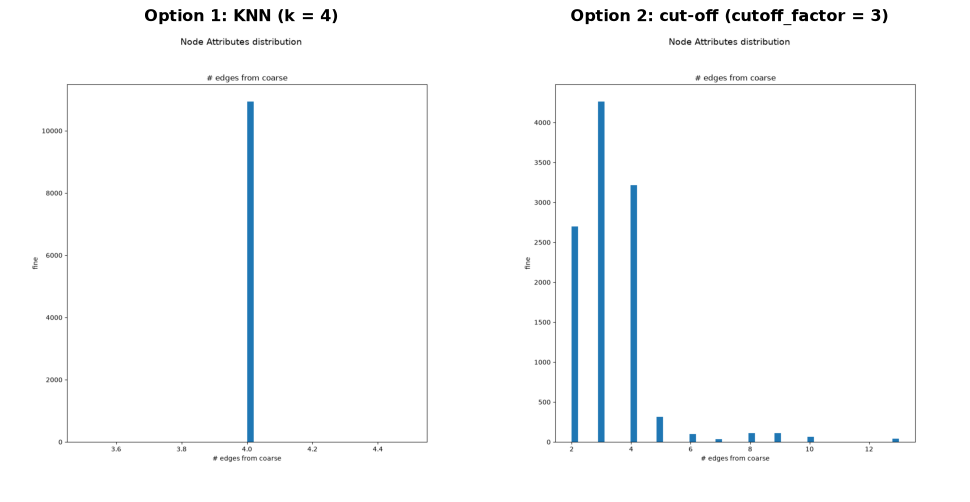

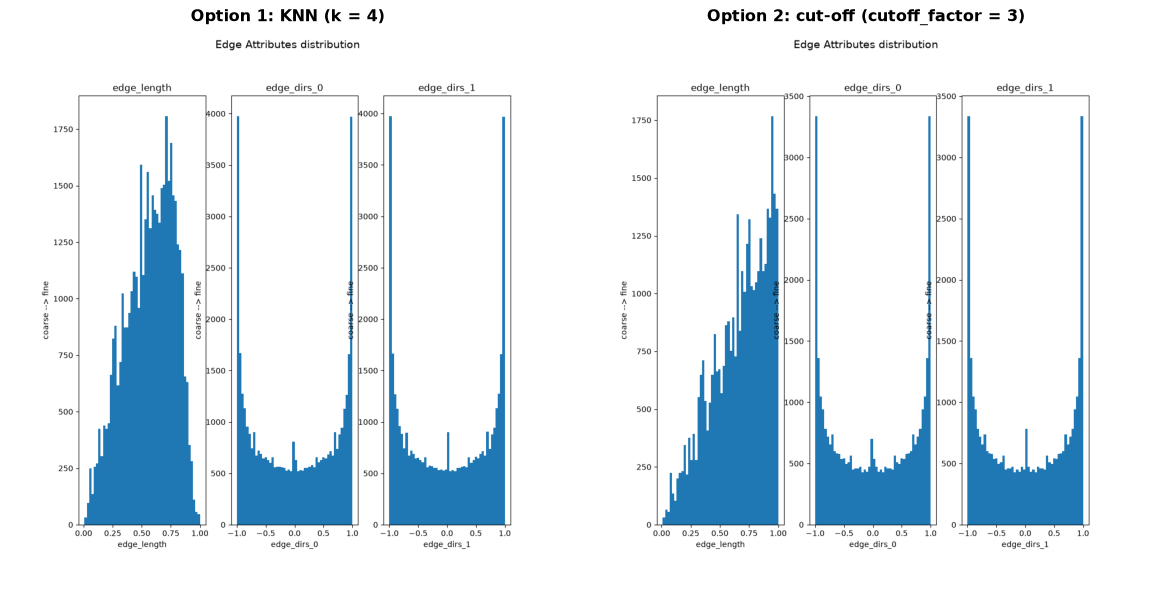

In [17]:
H.show_images({
    "Option 1: KNN (k = 4)": "graphs/inspect_knn/distribution_node_adjancency.png",
    "Option 2: cut-off (cutoff_factor = 3)": "graphs/inspect_cutoff/distribution_node_adjancency.png",
}, width=5.5)
plt.show()
H.show_images({
    "Option 1: KNN (k = 4)": "graphs/inspect_knn/distribution_edge_attributes.png",
    "Option 2: cut-off (cutoff_factor = 3)": "graphs/inspect_cutoff/distribution_edge_attributes.png",
}, width=6.5)
plt.show()

**What do we see?**

- **KNN** gives exactly 4 incoming edges to each fine node, everywhere. The edge length changes: the neighbourhood is larger where the coarse nodes are far from the fine node.
- **Cut-off** gives a fixed *radius*, thus the number of incoming edges changes from node to node. A fine node near a coarse node gets fewer edges than a fine node between coarse nodes. The edge lengths have an upper limit: the radius.
- The summary table shows the number of **isolated target nodes**: fine nodes without an incoming edge. A GNN cannot send information to these nodes. With `cutoff_factor: 3.0` there are none. With a small radius, some fine nodes are too far from all the coarse nodes. Try `cutoff_factor: 2.0` after the session, and look at `isolated_nodes.html`.
- The GNN of Part 4 works with the two graphs, because the aggregation (sum, mean, ...) accepts any number of incoming messages.

The standard AIFS configuration uses `CutOffEdges` for the encoder and `KNNEdges` for the decoder. The cut-off makes sure that each data grid point sends its information to at least one hidden node. KNN makes sure that each data grid point gets information from the same number of hidden nodes.

Now look at the interactive maps of Europe. You can zoom in and move the map. The colour of a node shows its number of connections. Click a name in the legend to hide or show the nodes or the edges. The tool also wrote `graph.html`, an interactive 3D globe. Open it in a new tab of your web browser.

> **NOTE:** The maps show only the nodes and edges inside the area. Thus, the nodes at the boundary of the area seem to have fewer edges.

In [18]:
H.show_html("graphs/inspect_knn_europe/coarse_to_fine.html", height=550)

In [19]:
H.show_html("graphs/inspect_cutoff_europe/coarse_to_fine.html", height=550)

We use **option 1 (KNN)** in the rest of the notebook. You can change `GRAPH_OPTION` to `"cutoff"` and run the notebook again: all the code below works with the two graphs.

> **NOTE:** anemoi-graphs keeps `edge_index` as `int32` to use less memory. PyTorch needs `int64` (`long`) indices, thus we convert it with `.long()`.

In [20]:
GRAPH_OPTION = "knn"  # or "cutoff"
graph = graphs[GRAPH_OPTION]
edges = graph["coarse", "to", "fine"]
edge_index = edges.edge_index.long()
print("edge_index:", tuple(edge_index.shape), " edge_length:", tuple(edges.edge_length.shape), " edge_dirs:", tuple(edges.edge_dirs.shape))
print("\nedge_index:\n", edge_index)

edge_index: (2, 43776)  edge_length: (43776, 1)  edge_dirs: (43776, 2)

edge_index:
 tensor([[    0,    19,     1,  ...,   988,  1006,  1005],
        [    0,     0,     0,  ..., 10943, 10943, 10943]])


## 4. Message passing

### 4.1 The three steps

A GNN layer updates the features $\mathbf{h}_i$ of each target node $i$ in three steps:

1. **Message.** Each edge $j \rightarrow i$ makes a message from the features of its source node, its target node and the edge:
$$\mathbf{m}_{j \to i} = \phi\left(\mathbf{h}_i, \mathbf{h}_j, \mathbf{e}_{j \to i}\right)$$
2. **Aggregation.** Each target node combines all its incoming messages:
$$\mathbf{M}_i = \bigoplus_{j \in \mathcal{N}(i)} \mathbf{m}_{j \to i}$$
Here, $\mathcal{N}(i)$ is the set of the source nodes of $i$, and $\bigoplus$ is a sum, a mean or a maximum.
3. **Update.** Each target node calculates its new features from its old features and the aggregated message:
$$\mathbf{h}_i' = \psi\left(\mathbf{h}_i, \mathbf{M}_i\right)$$

$\phi$ and $\psi$ are small neural networks, usually multi-layer perceptrons (MLPs). **All edges use the same $\phi$. All nodes use the same $\psi$.** This is the same idea as the shared kernel in a convolutional neural network. Thus, the number of weights does not change with the size of the graph.

The aggregation must give the same result for all orders of the incoming messages (the neighbours of a node have no order). A sum, a mean and a maximum have this property. Because of this, the same GNN works for any number of neighbours and any position of the nodes. The nodes can be a regular grid, a reduced Gaussian grid, an icosahedral mesh or a set of weather stations.

![Message step](assets/message_schema.png)
![Aggregation and update steps](assets/agg_update_schema.png)

### 4.2 Interpolation is message passing

You already know one message-passing algorithm: **interpolation**. With inverse-distance weights, the interpolated value at the fine node $i$ is:

$$T_i = \sum_{j \in \mathcal{N}(i)} w_{j \to i} \, T_j, \qquad w_{j \to i} = \frac{d_{j \to i}^{-2}}{\sum_{k \in \mathcal{N}(i)} d_{k \to i}^{-2}}$$

This is message passing with:

- the message $\mathbf{m}_{j \to i} = w_{j \to i} \, T_j$,
- a sum as the aggregation,
- no update ($\psi$ is the identity).

The weights $w_{j \to i}$ are fixed: they come from the distances. **A GNN learns the messages and the update from the data.** The figure shows the incoming edges of the fine node near Innsbruck. The labels show the interpolation weights.

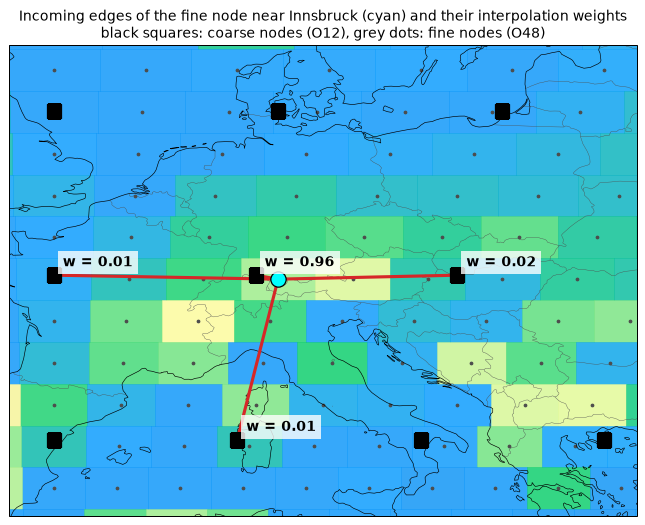

In [21]:
# Interpolation weights: inverse distance squared, normalised over the incoming edges of each target node
edge_length = edges.edge_length[:, 0]
w = 1.0 / (edge_length**2 + 1e-12)
w_sum = torch.zeros(train_ds.num_fine_nodes).index_add(0, edge_index[1], w)  # sum of w for each target node
interp_weights = w / w_sum[edge_index[1]]

innsbruck = H.nearest_node(train_ds.fine_lat, train_ds.fine_lon, 47.27, 11.39)
in_edges = torch.where(edge_index[1] == innsbruck)[0]

extent = (-2, 26, 37, 58)
fig = plt.figure(figsize=(9, 7))
ax = H.map_axes(fig, 1, 1, 1, extent=extent)
H.plot_field(ax, train_ds.fine_lat, train_ds.fine_lon, train_ds.orog_fine * 1000, cmap=H.OROG_CMAP, vmin=-500, vmax=3000,
             extent=extent, alpha=0.8)
H.plot_points(ax, train_ds.fine_lat, train_ds.fine_lon, s=4, c="0.3")
H.plot_edges(ax, train_ds.coarse_lat, train_ds.coarse_lon, train_ds.fine_lat, train_ds.fine_lon,
             edge_index[:, in_edges], colors="C3", linewidths=2.5, zorder=3)
H.plot_points(ax, train_ds.coarse_lat, train_ds.coarse_lon, s=120, c="k", marker="s", zorder=4)
H.plot_points(ax, train_ds.fine_lat[innsbruck], train_ds.fine_lon[innsbruck], s=150, c="cyan", edgecolors="k", zorder=5)
for e in in_edges:
    j = edge_index[0, e]
    ax.text(train_ds.coarse_lon[j] + 0.4, train_ds.coarse_lat[j] + 0.4, f"w = {interp_weights[e]:.2f}",
            fontsize=11, weight="bold", zorder=6, **H._transform(), bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
ax.set_title("Incoming edges of the fine node near Innsbruck (cyan) and their interpolation weights\n"
             "black squares: coarse nodes (O12), grey dots: fine nodes (O48)")
plt.show()

### ✏️ Exercise 2: message passing with PyTorch only

Write the function `message_passing_sum` with PyTorch only (no PyTorch Geometric). Then use it to calculate two baselines on the validation data (2021):

- **Baseline 1 (interpolation):** interpolate the coarse temperature to the fine grid.
- **Baseline 2 (interpolation + lapse rate):** interpolate the coarse orography in the same way. Then correct the temperature with the standard lapse rate: $T_i + \Gamma \, (z_i^\text{fine} - z_i^\text{interp})$, with $\Gamma = -6.5$ K/km.

The function must do the three steps:

1. **Message:** get the source value of each edge and multiply it by the weight of the edge. Use `edge_index[0]` to get the values.
2. **Aggregation:** add the messages that go to the same target node. Use `Tensor.index_add(dim, index, source)` with `edge_index[1]`.
3. **Update:** none.

> **NOTE:** The features can be any numbers. Here, we use a trick: we use the 730 validation times as 730 features of each node. Then one call to the function interpolates all the times.

<details><summary><b>💡 Hint 1</b> (click to open)</summary>

**Gather:** `x_src[edge_index[0]]` gives a tensor with shape `(num_edges, num_features)`. Row $e$ contains the features of the source node of edge $e$. Multiply it by `edge_weight.unsqueeze(-1)` (shape `(num_edges, 1)`).

</details>

<details><summary><b>💡 Hint 2</b> (click to open)</summary>

**Scatter:** `out.index_add(0, edge_index[1], messages)` adds row $e$ of `messages` to row `edge_index[1, e]` of `out`.

PyTorch Geometric does the same thing with `torch_geometric.utils.scatter(messages, edge_index[1], dim=0, dim_size=num_dst, reduce="sum")`. It also has `reduce="mean"` and `reduce="max"`.

</details>

In [22]:
def message_passing_sum(x_src, edge_index, edge_weight, num_dst):
    # x_src: (num_src, num_features), edge_index: (2, num_edges), edge_weight: (num_edges,)
    # 1. Message
    messages = x_src[edge_index[0]] * edge_weight.unsqueeze(-1)  # (num_edges, num_features)
    # 2. Aggregation (sum)
    out = torch.zeros(num_dst, x_src.shape[1], dtype=x_src.dtype)
    out = out.index_add(0, edge_index[1], messages)  # (num_dst, num_features)
    # 3. Update: none
    return out


# Baseline 1: interpolation. The 730 times are the features: shape (num_coarse, 730) -> (num_fine, 730)
t2m_coarse = torch.from_numpy(val_ds.t2m_coarse.T)
pred_interp = message_passing_sum(t2m_coarse, edge_index, interp_weights, val_ds.num_fine_nodes).T.numpy()

# Baseline 2: interpolation + standard lapse rate
orog_coarse = torch.from_numpy(val_ds.orog_coarse).unsqueeze(-1)
orog_interp = message_passing_sum(orog_coarse, edge_index, interp_weights, val_ds.num_fine_nodes)[:, 0].numpy()
pred_lapse = pred_interp + H.STANDARD_LAPSE_RATE * (val_ds.orog_fine - orog_interp)[None, :]

print(f"Validation RMSE, interpolation:              {rmse(pred_interp, val_ds.t2m_fine):.3f} K")
print(f"Validation RMSE, interpolation + lapse rate: {rmse(pred_lapse, val_ds.t2m_fine):.3f} K")

Validation RMSE, interpolation:              2.451 K
Validation RMSE, interpolation + lapse rate: 1.900 K


#### ✅ Solution

The two lines `x_src[edge_index[0]]` (**gather**) and `index_add(0, edge_index[1], ...)` (**scatter**) are the core of all GNN libraries. The memory and the time that they use change with the number of edges, not with the square of the number of nodes. This is why `edge_index` is better than the adjacency matrix.

The lapse-rate correction decreases the error by approximately 20 %. This shows that the fine orography contains important information. Now we want a model that learns *how* to use this information.

### 4.3 Message passing in PyTorch Geometric

PyTorch Geometric gives the base class `MessagePassing`. You write a subclass and you define:

- `message(...)`: the function $\phi$. It works on all the edges at the same time.
- `update(...)`: the function $\psi$. It works on all the target nodes at the same time.
- `aggr=...` in the constructor: the aggregation (`"sum"`, `"mean"`, `"max"`).

Then you call `self.propagate(edge_index, ...)`. This method does the gather, calls `message`, does the scatter (aggregation), and calls `update`.

**The `_i` and `_j` convention.** If you give `x=(x_src, x_dst)` to `propagate`, you can use the arguments `x_j` and `x_i` in `message`. PyTorch Geometric gathers them for you:

- `x_j = x_src[edge_index[0]]`: the features of the **source** node of each edge.
- `x_i = x_dst[edge_index[1]]`: the features of the **target** node of each edge.

This works for all the tensors that you give to `propagate`. For example, if you give `q=...`, you can use `q_i` in `message`.

Below, the interpolation from Exercise 2 is a `MessagePassing` layer. It gives the same result.

In [23]:
class InterpolationLayer(MessagePassing):
    def __init__(self):
        super().__init__(aggr="sum")

    def forward(self, x_src, x_dst, edge_index, edge_weight):
        return self.propagate(edge_index, x=(x_src, x_dst), edge_weight=edge_weight)

    def message(self, x_j, edge_weight):
        # x_j: (num_edges, num_features), the features of the source node of each edge
        return x_j * edge_weight.unsqueeze(-1)

    def update(self, aggr_out):
        return aggr_out


pyg_interp = InterpolationLayer()(t2m_coarse, torch.zeros(val_ds.num_fine_nodes, 1), edge_index, interp_weights)
print("Same result as message_passing_sum:", torch.allclose(pyg_interp.T, torch.from_numpy(pred_interp)))

Same result as message_passing_sum: True


### 4.4 The downscaling GNN

Now we write a GNN layer that **learns** its messages. Its structure is:

```
coarse features x_src ──► encoder MLP ──► h_j ─┐
                                               ├──► message MLP φ(h_i, h_j, e_ji) ──► sum over j ──► M_i ─┐
fine features x_dst ──► encoder MLP ──► h_i ───┘                                                          │
          │                                                                                               ▼
          └───────────────────────────────────────────────────────────► h_i' = h_i + ψ(h_i, M_i) ──► decoder ──► ΔT_i
```

1. Two **encoders** (MLPs) change the features of the coarse nodes and of the fine nodes into vectors of size `hidden_dim`.
2. The **message** MLP $\phi$ uses the concatenation $[\mathbf{h}_i, \mathbf{h}_j, \mathbf{e}_{j\to i}]$. The edge features $\mathbf{e}_{j\to i}$ are the edge length and the edge direction.
3. The **aggregation** is a sum.
4. The **update** MLP $\psi$ uses the concatenation $[\mathbf{h}_i, \mathbf{M}_i]$. We add its output to $\mathbf{h}_i$ (a *residual connection*).
5. A linear **decoder** gives one number for each fine node.

**Residual learning.** The GNN does not predict the temperature directly. It predicts a **correction** $\Delta T_i$ to Baseline 2 (interpolation + lapse rate):

$$T_i = \underbrace{T_i^\text{interp} + \Gamma \, (z_i^\text{fine} - z_i^\text{interp})}_{\text{physics: Baseline 2}} + \underbrace{\Delta T_i}_{\text{GNN}}$$

The physics gives a first guess, and the GNN learns only what the physics does not know. This makes the training easier. The wrapper `GraphDownscaler` adds the baseline. AIFS uses a similar idea: it predicts the change of the state over one time step, not the new state.

### ✏️ Exercise 3: complete the GNN layer

Replace the `???` in the class below:

1. The input size of `self.message_mlp`.
2. The input size of `self.update_mlp`.
3. The concatenation in `message()`.

Then run the test cell below it.

<details><summary><b>💡 Hint 1</b> (click to open)</summary>

After the encoders, $\mathbf{h}_i$ and $\mathbf{h}_j$ have `hidden_dim` features each. The edge features have `edge_dim` features. What is the size of their concatenation?

</details>

<details><summary><b>💡 Hint 2</b> (click to open)</summary>

In `message(self, x_i, x_j, edge_attr)`, `x_i` and `x_j` are the *encoded* features $\mathbf{h}_i$ and $\mathbf{h}_j$, because `forward` gives `x=(h_src, h_dst)` to `propagate`. Use `torch.cat([...], dim=-1)`.

</details>

In [24]:
def mlp(in_dim: int, out_dim: int, hidden_dim: int | None = None) -> nn.Sequential:
    hidden_dim = hidden_dim or out_dim
    return nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, out_dim))

In [25]:
class DownscalingGNN(MessagePassing):
    def __init__(self, in_channels_src: int, in_channels_dst: int, edge_dim: int, hidden_dim: int, out_channels: int):
        super().__init__(aggr="sum")
        self.encoder_src = mlp(in_channels_src, hidden_dim)
        self.encoder_dst = mlp(in_channels_dst, hidden_dim)
        self.message_mlp = mlp(2 * hidden_dim + edge_dim, hidden_dim)
        self.update_mlp = mlp(2 * hidden_dim, hidden_dim)
        self.decoder = nn.Linear(hidden_dim, out_channels)

    def forward(self, x_src, x_dst, edge_index, edge_attr):
        h_src = self.encoder_src(x_src)  # (num_src, hidden_dim)
        h_dst = self.encoder_dst(x_dst)  # (num_dst, hidden_dim)
        h_dst = self.propagate(edge_index, x=(h_src, h_dst), edge_attr=edge_attr)  # (num_dst, hidden_dim)
        return self.decoder(h_dst)  # (num_dst, out_channels)

    def message(self, x_i, x_j, edge_attr):
        # x_i: (num_edges, hidden_dim) target, x_j: (num_edges, hidden_dim) source, edge_attr: (num_edges, edge_dim)
        return self.message_mlp(torch.cat([x_i, x_j, edge_attr], dim=-1))

    def update(self, aggr_out, x):
        # aggr_out: (num_dst, hidden_dim), x = (h_src, h_dst)
        h_dst = x[1]
        return h_dst + self.update_mlp(torch.cat([h_dst, aggr_out], dim=-1))

#### ✅ Solution

- The message MLP gets $[\mathbf{h}_i, \mathbf{h}_j, \mathbf{e}_{j\to i}]$: `hidden_dim + hidden_dim + edge_dim` features.
- The update MLP gets $[\mathbf{h}_i, \mathbf{M}_i]$: `2 * hidden_dim` features.

The message uses $\mathbf{h}_i$ **and** $\mathbf{h}_j$. Thus, the message from a coarse node can be different for each fine node. For example, it can depend on the height of the fine node. The interpolation cannot do this.

In [26]:
# Test: run the layer on a small random graph and check the shapes
_layer = DownscalingGNN(in_channels_src=3, in_channels_dst=10, edge_dim=3, hidden_dim=8, out_channels=1)
_ei = torch.tensor([[0, 1, 2, 2], [0, 0, 1, 2]])  # 3 source nodes, 3 target nodes, 4 edges
_out = _layer(torch.randn(3, 3), torch.randn(3, 10), _ei, torch.randn(4, 3))
assert _out.shape == (3, 1), f"The output has the shape {tuple(_out.shape)}, but it must be (3, 1)."
print("Test passed. Output shape:", tuple(_out.shape))

Test passed. Output shape: (3, 1)


## 5. Train and evaluate the GNN

**Batches of graphs.** PyTorch Geometric layers expect node features with the shape `(num_nodes, num_features)`, without a batch dimension. How can we train with batches? We put the $B$ copies of the graph side by side, in **one large graph with $B$ parts that have no connection**. In copy $b$, all coarse node indices increase by $b \times 1\,008$ and all fine node indices increase by $b \times 10\,944$. The class `GraphDownscaler` in `gnn_helpers.py` does this. PyTorch Geometric uses the same method for batches of different graphs (see `torch_geometric.data.Batch`).

**Training.** We train for a fixed number of epochs with the Adam optimiser and the mean squared error of the normalised temperature. After each epoch, the training loop calculates the RMSE on the validation data (2021), in kelvin.

> **NOTE:** On a GPU, the cell below trains for 20 epochs (less than one minute). On a CPU, it trains for 5 epochs only (approximately 5 minutes with 8 cores). With 5 epochs, the result is a little worse, but the conclusions do not change.

In [27]:
HIDDEN_DIM = 32
EPOCHS = 20 if DEVICE.type == "cuda" else 5
BATCH_SIZE = 8
LEARNING_RATE = 5e-3

edge_attr = torch.cat([edges.edge_length, edges.edge_dirs], dim=-1)  # (num_edges, 3)
print("Edge features:", tuple(edge_attr.shape))

H.set_seed(0)
gnn = DownscalingGNN(
    in_channels_src=train_ds.num_src_features,
    in_channels_dst=train_ds.num_dst_features,
    edge_dim=edge_attr.shape[1],
    hidden_dim=HIDDEN_DIM,
    out_channels=1,
)
# Residual learning: the GNN output is added to Baseline 2 (interpolation + lapse rate).
# The lapse rate is in normalised units: K/km divided by the standard deviation of the temperature.
model = GraphDownscaler(gnn, edge_index, edge_attr, interp_weights=interp_weights,
                        lapse_rate=H.STANDARD_LAPSE_RATE / train_ds.t2m_std).to(DEVICE)
print(f"Number of trainable parameters: {H.count_parameters(model)}")

Edge features: (43776, 3)
Number of trainable parameters: 8993


In [28]:
history_gnn = H.train_model(model, train_ds, val_ds, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE)

Epoch  1/5  train loss 0.0153  validation RMSE 1.843 K  (47 s)
Epoch  2/5  train loss 0.0128  validation RMSE 1.839 K  (89 s)
Epoch  3/5  train loss 0.0119  validation RMSE 1.734 K  (132 s)
Epoch  4/5  train loss 0.0112  validation RMSE 1.708 K  (173 s)
Epoch  5/5  train loss 0.0110  validation RMSE 1.703 K  (210 s)


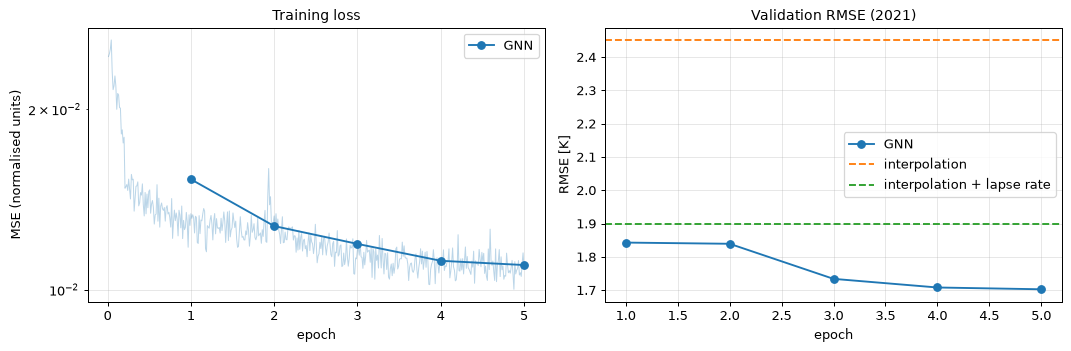

In [29]:
baselines = {"interpolation": rmse(pred_interp, val_ds.t2m_fine), "interpolation + lapse rate": rmse(pred_lapse, val_ds.t2m_fine)}
H.plot_loss_curves({"GNN": history_gnn}, baselines)
plt.show()

We compare the GNN with the two baselines on the validation year 2021. The table shows the RMSE over all the points, at 00 UTC, at 12 UTC, over land and in the mountains. Here, "mountains" are the fine nodes with an orography higher than 1 000 m.

In [30]:
pred_gnn = H.predict(model, val_ds)
predictions = {"interpolation": pred_interp, "interp. + lapse rate": pred_lapse, "GNN": pred_gnn}

hours = (val_ds.times - val_ds.times.astype("datetime64[D]")).astype(int)
regions = {"all": np.ones(val_ds.num_fine_nodes, bool), "land": val_ds.lsm_fine > 0.5, "mountains": val_ds.orog_fine > 1.0}

print(f"{'':22s} {'all':>7s} {'00 UTC':>8s} {'12 UTC':>8s} {'land':>7s} {'mountains':>10s}")
for name, pred in predictions.items():
    t = val_ds.t2m_fine
    print(f"{name:22s} {rmse(pred, t):6.3f}K {rmse(pred[hours == 0], t[hours == 0]):7.3f}K {rmse(pred[hours == 12], t[hours == 12]):7.3f}K "
          f"{rmse(pred[:, regions['land']], t[:, regions['land']]):6.3f}K {rmse(pred[:, regions['mountains']], t[:, regions['mountains']]):9.3f}K")

                           all   00 UTC   12 UTC    land  mountains
interpolation           2.451K   2.446K   2.457K  3.978K     5.713K
interp. + lapse rate    1.900K   1.852K   1.947K  2.840K     3.338K
GNN                     1.703K   1.687K   1.719K  2.548K     2.933K


Now look at one case in detail: Asia on 12 January 2021, 00 UTC. The top row shows the fields. The bottom row shows the orography and the errors (prediction − truth).

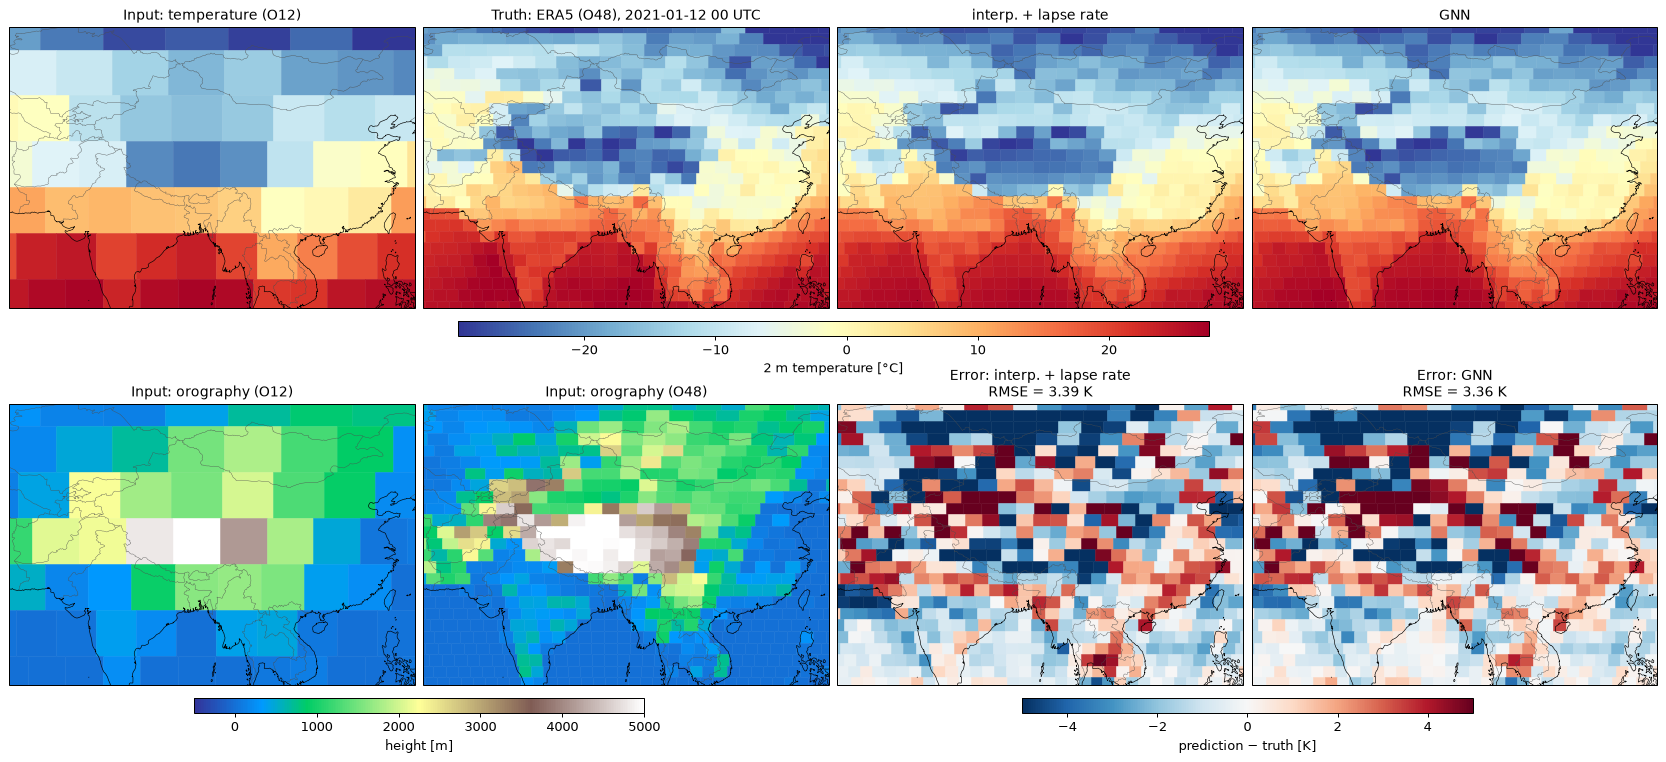

In [31]:
ASIA = (60, 125, 10, 55)
H.plot_downscaling_example(val_ds, EXAMPLE, {"interp. + lapse rate": pred_lapse, "GNN": pred_gnn}, extent=ASIA)
plt.show()

Where does the GNN improve the result? The maps show the RMSE at each point over all the validation times. The last map shows the difference between the GNN and the best baseline (blue: the GNN is better).

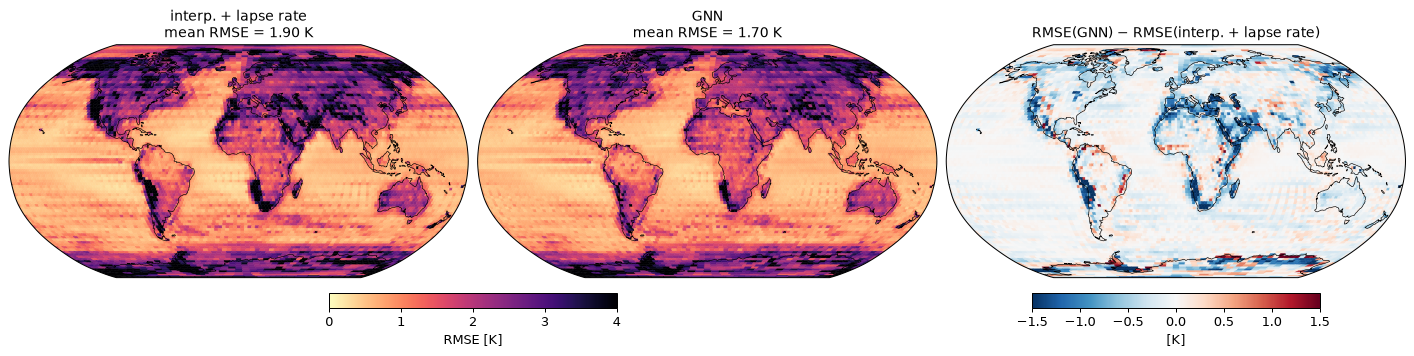

In [32]:
H.plot_rmse_maps(val_ds, {"interp. + lapse rate": pred_lapse, "GNN": pred_gnn}, reference="interp. + lapse rate")
plt.show()

**What do we see?**

- The interpolation has large errors over land, in particular in the mountains. The lapse-rate correction removes approximately 40 % of the error in the mountains.
- The GNN is better than the two baselines at 00 UTC and at 12 UTC, over land and in the mountains.
- The largest improvements are at the **coasts** and at the edges of the **mountain ranges**, for example along the Andes. A coarse O12 cell on a coast contains land and sea, thus the coarse temperature is a mix of the two. The lapse rate cannot correct this. The GNN uses the fine land-sea mask and learns the difference between land and sea. This difference also changes with the time of day and the season.
- Over the oceans, the improvement is small. The temperature over the sea changes slowly in space, thus the interpolation is already good.
- At a small number of points, the GNN is worse than the baseline (red).
- The errors are still large in some regions, for example over the Tibetan Plateau, Siberia, Canada and Antarctica. Can you think of ways to reduce the error further?

## 6. Summary and next steps

**Key points**

- A **graph** is a set of nodes and edges. PyTorch Geometric and anemoi-graphs keep the edges in `edge_index`, a `(2, num_edges)` tensor of source and target indices.
- **anemoi-datasets** reads the training data of data-driven weather models. The grid points are in one dimension, thus the grid can be any grid.
- **anemoi-graphs** makes the graphs from node builders and edge builders in a YAML configuration. `anemoi-graphs inspect` shows the result. KNN gives the same number of edges to each target node. A cut-off radius gives the same maximum distance.
- **Message passing** has three steps: message, aggregation and update. Interpolation is a message-passing operation with fixed weights. A GNN learns the messages and the update.
- The core operations are **gather** (`x[edge_index[0]]`) and **scatter** (`index_add` on `edge_index[1]`). Their cost changes with the number of edges.
- The same GNN works on all grids: the aggregation accepts any number of neighbours in any order.

**More tasks (no solutions)**

- Train the GNN with **option 2** (the cut-off graph): set `GRAPH_OPTION = "cutoff"`. Compare `aggr="sum"` and `aggr="mean"`. Why can the result change with the cut-off graph, but not with the KNN graph?
- Change `cutoff_factor` to 2.0. How many fine nodes are isolated? What does the GNN predict for them?
- Add a **processor**: a second set of edges from `"fine"` to `"fine"` (for example `KNNEdges` with 8 neighbours) and a second message-passing layer. Then the fine nodes can share information.
- Add more input variables. The dataset also contains, for example, the temperature at 850 hPa (`t_850`) and the total column water (`tcw`).

**References and documentation**

- anemoi-datasets: <https://anemoi.readthedocs.io/projects/datasets/en/latest/>
- anemoi-graphs: <https://anemoi.readthedocs.io/projects/graphs/en/latest/>
- anemoi-models (the GNN and graph transformer layers of AIFS): <https://anemoi.readthedocs.io/projects/models/en/latest/>
- PyTorch Geometric, "Creating message passing networks": <https://pytorch-geometric.readthedocs.io/en/latest/tutorial/create_gnn.html>
- Battaglia et al. (2018), *Relational inductive biases, deep learning, and graph networks*, <https://arxiv.org/abs/1806.01261>
- Lam et al. (2023), *Learning skillful medium-range global weather forecasting* (GraphCast), Science, <https://doi.org/10.1126/science.adi2336>
- Lang et al. (2024), *AIFS – ECMWF's data-driven forecasting system*, <https://arxiv.org/abs/2406.01465>
- Hersbach et al. (2020), *The ERA5 global reanalysis*, QJRMS, <https://doi.org/10.1002/qj.3803>

## 7. ⭐ Optional exercise: a graph transformer layer

This part is not in the 50 minutes of the session. Do it after the session, or if you have time.

The encoder and the decoder of AIFS do not use an MLP to make the messages. They use **attention**, as in a transformer. In anemoi-models, this layer is the `GraphTransformer`. With attention, each target node calculates a **weight for each incoming edge**. The node "decides" which neighbours are important. The weights of the incoming edges of a node are positive and their sum is 1, as in an interpolation. But the weights change with the data.

For each edge $j \to i$ and each attention head:

1. **Projections.** The target node makes a *query*, the source node makes a *key* and a *value*. The edge features go into the key and the value:
$$\mathbf{q}_i = W_Q \mathbf{h}_i, \qquad \mathbf{k}_{j\to i} = W_K \mathbf{h}_j + W_E \mathbf{e}_{j\to i}, \qquad \mathbf{v}_{j\to i} = W_V \mathbf{h}_j + W_E \mathbf{e}_{j\to i}$$
2. **Score.** The scaled dot product: $s_{j\to i} = \mathbf{q}_i \cdot \mathbf{k}_{j\to i} / \sqrt{C}$, with $C$ the size of one head.
3. **Softmax over the incoming edges of each target node:**
$$\alpha_{j\to i} = \frac{\exp(s_{j\to i})}{\sum_{k \in \mathcal{N}(i)} \exp(s_{k\to i})}$$
4. **Message:** $\mathbf{m}_{j\to i} = \alpha_{j\to i}\, \mathbf{v}_{j\to i}$. The aggregation is a sum, thus $\mathbf{M}_i = \sum_j \alpha_{j\to i} \mathbf{v}_{j\to i}$.

With $H$ heads, the vectors of size `hidden_dim` are split into $H$ parts of size $C = $ `hidden_dim / H`. Each head calculates its own attention weights. Then the $H$ parts are put together again.

The difference from the attention of a normal transformer: the softmax is not over all the tokens. It is **only over the incoming edges of each node**. The graph defines which nodes can "see" each other.

### ✏️⭐ Exercise 4: write a graph transformer layer

Complete the class `GraphTransformerDownscaler` below:

1. In `forward()`: calculate the query, the key, the value and the edge embedding. Give them to `propagate()`.
2. In `message()`: do steps 1 to 4 above, for $H$ heads. Keep the attention weights in `self.attention` (for the plots).

The encoders, the update and the decoder are the same as in `DownscalingGNN`. Then:

3. Run the test cell. It checks the shapes and that the sum of the attention weights of each node is 1.
4. Train the model with the same settings as the GNN. Compare the RMSE.
5. Look at the attention weights of some fine nodes (the plot cells below are complete).

<details><summary><b>💡 Hint 1</b> (click to open)</summary>

The softmax over the incoming edges of each node is in PyTorch Geometric: `torch_geometric.utils.softmax(src, index)`. `src` has the shape `(num_edges, num_heads)`. `index` gives the target node of each edge. `MessagePassing` gives `index` to `message()` if you add `index` to its arguments. You also get `ptr` and `size_i`: give them to `softmax(src, index, ptr, size_i)`.

</details>

<details><summary><b>💡 Hint 2</b> (click to open)</summary>

In `forward()`:

```python
q = self.lin_query(h_dst)   # (num_dst, hidden_dim)
k = self.lin_key(h_src)     # (num_src, hidden_dim)
v = self.lin_value(h_src)   # (num_src, hidden_dim)
e = self.lin_edge(edge_attr)  # (num_edges, hidden_dim)
m = self.propagate(edge_index, q=q, k=k, v=v, e=e, size=(h_src.shape[0], h_dst.shape[0]))
```

Because of the `_i` / `_j` convention, `message()` gets these tensors:

- `q_i`: the query of the target node of each edge.
- `k_j` and `v_j`: the key and the value of the source node of each edge.
- `e`: the edge embedding (one row for each edge).

We give `size=...` because `x` is not an argument of `propagate()` here. Without `x`, PyTorch Geometric cannot know the number of target nodes.

</details>

<details><summary><b>💡 Hint 3</b> (click to open)</summary>

In `message()`, use `.view(-1, H, C)` to split the last dimension into heads, and `.view(-1, H * C)` to put them together again:

```python
k_j = (k_j + e).view(-1, H, C)
...
scores = (q_i * k_j).sum(dim=-1) / C**0.5           # (num_edges, H)
alpha = softmax(scores, index, ptr, size_i)          # (num_edges, H)
out = v_j * alpha.unsqueeze(-1)                      # (num_edges, H, C)
```

</details>

In [33]:
class GraphTransformerDownscaler(MessagePassing):
    def __init__(
        self,
        in_channels_src: int,
        in_channels_dst: int,
        edge_dim: int,
        hidden_dim: int,
        out_channels: int,
        num_heads: int = 4,
    ):
        super().__init__(aggr="sum")
        assert hidden_dim % num_heads == 0, "hidden_dim must be a multiple of num_heads"
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        self.encoder_src = mlp(in_channels_src, hidden_dim)
        self.encoder_dst = mlp(in_channels_dst, hidden_dim)
        self.lin_query = nn.Linear(hidden_dim, hidden_dim)
        self.lin_key = nn.Linear(hidden_dim, hidden_dim)
        self.lin_value = nn.Linear(hidden_dim, hidden_dim)
        self.lin_edge = nn.Linear(edge_dim, hidden_dim)
        self.update_mlp = mlp(2 * hidden_dim, hidden_dim)
        self.decoder = nn.Linear(hidden_dim, out_channels)
        self.attention = None

    def forward(self, x_src, x_dst, edge_index, edge_attr):
        h_src = self.encoder_src(x_src)  # (num_src, hidden_dim)
        h_dst = self.encoder_dst(x_dst)  # (num_dst, hidden_dim)

        q = self.lin_query(h_dst)  # (num_dst, hidden_dim)
        k = self.lin_key(h_src)  # (num_src, hidden_dim)
        v = self.lin_value(h_src)  # (num_src, hidden_dim)
        e = self.lin_edge(edge_attr)  # (num_edges, hidden_dim)
        m = self.propagate(edge_index, q=q, k=k, v=v, e=e, size=(h_src.shape[0], h_dst.shape[0]))  # (num_dst, hidden_dim)

        h_dst = h_dst + self.update_mlp(torch.cat([h_dst, m], dim=-1))
        return self.decoder(h_dst)

    def message(self, q_i, k_j, v_j, e, index, ptr, size_i):
        H, C = self.num_heads, self.head_dim
        # 1. Add the edge embedding to the key and the value, and split into heads
        q_i = q_i.view(-1, H, C)
        k_j = (k_j + e).view(-1, H, C)
        v_j = (v_j + e).view(-1, H, C)
        # 2. Scaled dot product
        scores = (q_i * k_j).sum(dim=-1) / C**0.5  # (num_edges, H)
        # 3. Softmax over the incoming edges of each target node
        alpha = softmax(scores, index, ptr, size_i)  # (num_edges, H)
        self.attention = alpha.detach()
        # 4. Weighted values, then put the heads together again
        return (v_j * alpha.unsqueeze(-1)).view(-1, H * C)  # (num_edges, hidden_dim)

In [34]:
# Test: shapes, and the sum of the attention weights of each target node must be 1
_layer = GraphTransformerDownscaler(in_channels_src=3, in_channels_dst=10, edge_dim=3, hidden_dim=8, out_channels=1, num_heads=2)
_ei = torch.tensor([[0, 1, 2, 2], [0, 0, 1, 2]])
_out = _layer(torch.randn(3, 3), torch.randn(3, 10), _ei, torch.randn(4, 3))
assert _out.shape == (3, 1), f"The output has the shape {tuple(_out.shape)}, but it must be (3, 1)."
assert _layer.attention.shape == (4, 2), f"The attention has the shape {tuple(_layer.attention.shape)}, but it must be (4, 2)."
_sums = torch.zeros(3, 2).index_add(0, _ei[1], _layer.attention)
assert torch.allclose(_sums, torch.ones(3, 2)), f"The sums of the attention weights are not 1:\n{_sums}"
print("Test passed.")

Test passed.


In [35]:
H.set_seed(0)
gt = GraphTransformerDownscaler(
    in_channels_src=train_ds.num_src_features,
    in_channels_dst=train_ds.num_dst_features,
    edge_dim=edge_attr.shape[1],
    hidden_dim=HIDDEN_DIM,
    out_channels=1,
    num_heads=4,
)
model_gt = GraphDownscaler(gt, edge_index, edge_attr, interp_weights=interp_weights,
                           lapse_rate=H.STANDARD_LAPSE_RATE / train_ds.t2m_std).to(DEVICE)
print(f"Number of trainable parameters: {H.count_parameters(model_gt)}")
history_gt = H.train_model(model_gt, train_ds, val_ds, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE)

Number of trainable parameters: 9057
Epoch  1/5  train loss 0.0150  validation RMSE 1.844 K  (35 s)
Epoch  2/5  train loss 0.0125  validation RMSE 1.773 K  (70 s)
Epoch  3/5  train loss 0.0113  validation RMSE 1.680 K  (105 s)
Epoch  4/5  train loss 0.0105  validation RMSE 1.655 K  (142 s)
Epoch  5/5  train loss 0.0103  validation RMSE 1.647 K  (178 s)


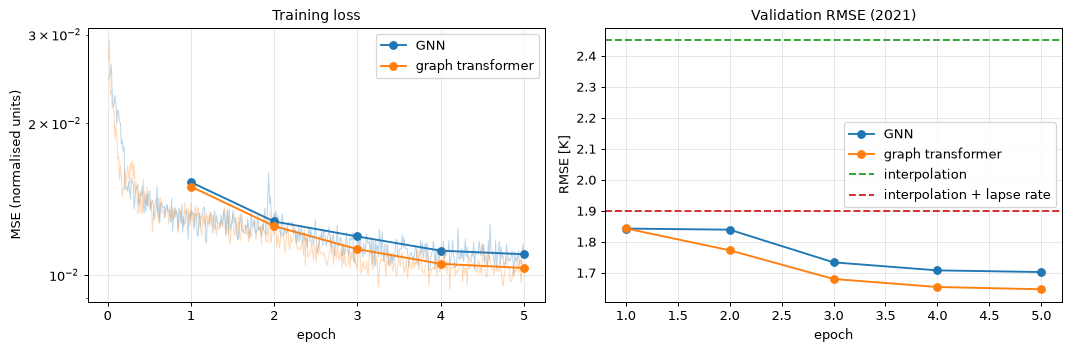

interpolation          validation RMSE = 2.451 K
interp. + lapse rate   validation RMSE = 1.900 K
GNN                    validation RMSE = 1.703 K
graph transformer      validation RMSE = 1.647 K


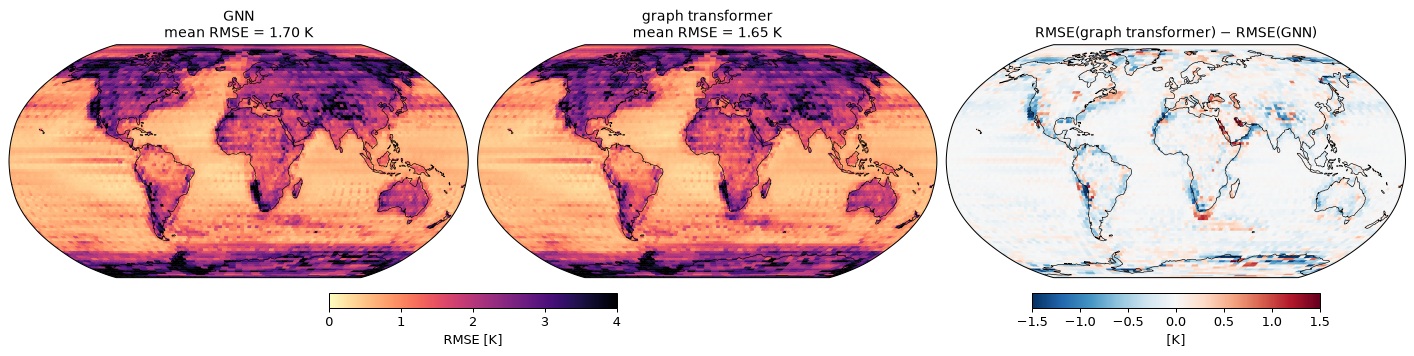

In [36]:
pred_gt = H.predict(model_gt, val_ds)
predictions["graph transformer"] = pred_gt
H.plot_loss_curves({"GNN": history_gnn, "graph transformer": history_gt}, baselines)
plt.show()
for name, pred in predictions.items():
    print(f"{name:22s} validation RMSE = {rmse(pred, val_ds.t2m_fine):.3f} K")
H.plot_rmse_maps(val_ds, {"GNN": pred_gnn, "graph transformer": pred_gt}, reference="GNN")
plt.show()

#### Look at the attention weights

We run the model on one time and keep the attention weights. The plot shows the incoming edges of four fine nodes: a high plateau (Lhasa, Tibet), a mountain range (La Paz, Andes), a coast (Lima) and a desert (Tamanrasset, Sahara). The width and the colour of each edge show its attention weight (the mean over the heads).

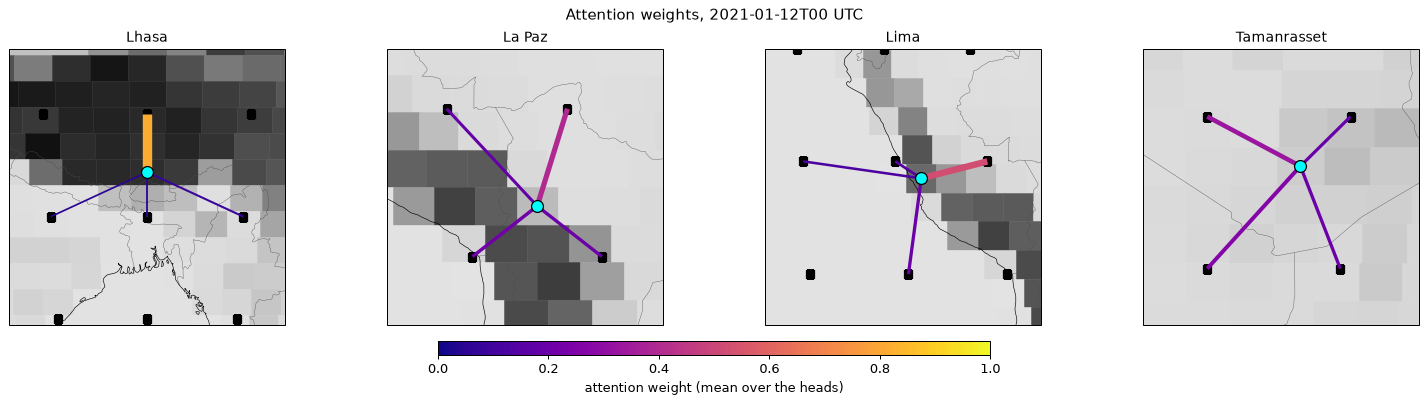

Interpolation weights (fixed) and attention weights:
  Lhasa        interpolation: [0.49 0.3  0.11 0.11]   attention: [0.06 0.81 0.08 0.05]
  La Paz       interpolation: [0.33 0.33 0.21 0.12]   attention: [0.21 0.22 0.4  0.18]
  Lima         interpolation: [0.73 0.15 0.07 0.05]   attention: [0.15 0.52 0.2  0.13]
  Tamanrasset  interpolation: [0.48 0.22 0.18 0.12]   attention: [0.19 0.33 0.2  0.27]


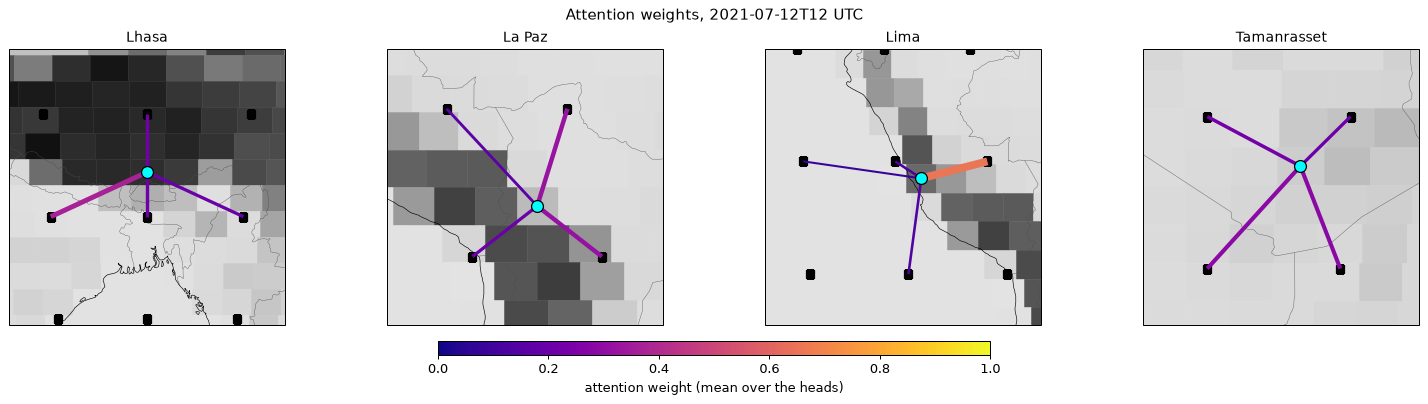

Interpolation weights (fixed) and attention weights:
  Lhasa        interpolation: [0.49 0.3  0.11 0.11]   attention: [0.21 0.22 0.2  0.37]
  La Paz       interpolation: [0.33 0.33 0.21 0.12]   attention: [0.31 0.2  0.32 0.16]
  Lima         interpolation: [0.73 0.15 0.07 0.05]   attention: [0.13 0.66 0.13 0.08]
  Tamanrasset  interpolation: [0.48 0.22 0.18 0.12]   attention: [0.2  0.23 0.28 0.29]


In [37]:
places = {"Lhasa": (29.65, 91.10), "La Paz": (-16.50, -68.15), "Lima": (-12.05, -77.04), "Tamanrasset": (22.79, 5.52)}
place_nodes = {name: H.nearest_node(val_ds.fine_lat, val_ds.fine_lon, la, lo) for name, (la, lo) in places.items()}

def attention_for_sample(model, ds, idx):
    model.eval()
    x_src, x_dst, _ = ds[idx]
    with torch.no_grad():
        model(x_src[None].to(DEVICE), x_dst[None].to(DEVICE))
    return model.gnn.attention.mean(dim=-1).cpu().numpy()  # mean over the heads, shape (num_edges,)

for idx in (EXAMPLE, val_ds.time_index("2021-07-12T12")):
    att = attention_for_sample(model_gt, val_ds, idx)
    H.plot_attention(val_ds, edge_index.numpy(), att, place_nodes,
                     title=f"Attention weights, {np.datetime_as_string(val_ds.times[idx], unit='h')} UTC")
    plt.show()
    print("Interpolation weights (fixed) and attention weights:")
    for name, node in place_nodes.items():
        e_in = np.where(edge_index[1].numpy() == node)[0]
        print(f"  {name:12s} interpolation: {np.round(interp_weights[e_in].numpy(), 2)}   attention: {np.round(att[e_in], 2)}")

#### ✅ Solution

**About the results** (your numbers can be a little different):

- The graph transformer is a little better than the GNN with the MLP messages, with almost the same number of weights. The softmax gives weights that are positive and have a sum of 1. This is a good *inductive bias* for this task, because the result is a weighted mean of the neighbours, as in an interpolation.
- The attention weights are **not** the interpolation weights. For example, for Lima the interpolation gives most of the weight to the nearest coarse node. The attention gives most of the weight to a different coarse node.
- In this small model, the attention weights change only a little between the two times. They depend more on the position of the nodes than on the weather.

- The attention weights alone do not explain the prediction. The values $\mathbf{v}_{j\to i}$ and the update MLP also change the result. Be careful when you interpret attention weights as "importance".
- The attention weights in the plot are a mean over the heads. Each head can learn a different pattern. Change `.mean(dim=-1)` in `attention_for_sample` to look at one head.

**Questions to think about:**

1. Train the graph transformer with `num_nearest_neighbours: 8` or `16` (change the YAML file in Section 3.1 and run the notebook again). Does the RMSE change? Do the far nodes get small attention weights?
2. Remove the edge features: give `edge_attr = torch.zeros_like(edge_attr)`. What happens to the RMSE, and why?
3. Train the graph transformer with the cut-off graph (`GRAPH_OPTION = "cutoff"`). Is the difference from the GNN larger or smaller than with the KNN graph?